In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [89]:
data = pd.read_csv("../data/processed/prices_ix_secs.csv")

In [87]:
# Проверяем наличие пропущенных значений
missing_values = data.isnull().sum()
print("Пропущенные значения:",missing_values)

Пропущенные значения: Unnamed: 0      0
trade_date      0
close_ix        0
boardid         0
ticker          0
open          238
high          238
low           238
close         238
volume          0
value           0
numtrades       0
sector          0
dtype: int64


Пропущенные значения относятся к гэпам во время приостановки торгов по акции, начале торгов, процедуре смены юрлица и тикера.

In [86]:
#Проверим наличие дубликатов
duplicates=data.duplicated()
print("Дубликаты:",duplicates.sum())


Дубликаты: 0


In [28]:
# Выводим количество пропущенных значений для каждого столбца
print("Количество пропущенных значений по столбцам:")
print(missing_values)

Количество пропущенных значений по столбцам:
Unnamed: 0      0
trade_date      0
close_ix        0
boardid         0
ticker          0
open          238
high          238
low           238
close         238
volume          0
value           0
numtrades       0
sector          0
dtype: int64


In [90]:
data.head()

,trade_date,close_ix,boardid,ticker,open,high,low,close,volume,value,numtrades,sector
0,2018-01-03,2152.97,TQBR,AFKS,12.485,12.55,12.26,12.350,20687500,256119052.0,5071,финансы
1,2018-01-03,2152.97,TQBR,AFLT,139.100,140.95,138.60,140.400,2126700,296982430.0,3163,транспорт
2,2018-01-03,2152.97,TQBR,ALRS,75.210,75.96,75.15,75.810,3908500,295337171.0,3719,металлы и добыча
3,2018-01-03,2152.97,TQBR,BSPB,54.800,54.85,54.55,54.850,8730,477857.5,49,финансы
4,2018-01-03,2152.97,TQBR,CBOM,4.680,4.74,4.68,4.735,1065500,5039994.8,294,финансы


In [32]:
data.groupby('sector')['ticker'].unique()

sector
информационные технологии                 [OZON, VKCO, POSI, YDEX, HEAD, CNRU]
металлы и добыча             [ALRS, CHMF, GMKN, MAGN, NLMK, PLZL, RUAL, ENP...
нефть и газ                  [GAZP, LKOH, NVTK, ROSN, SNGS, SNGSP, TATN, TA...
потребительский сектор                                        [MDMG, X5, RAGR]
телекоммуникации                                                  [MTSS, RTKM]
транспорт                                                         [AFLT, FLOT]
финансы                      [AFKS, BSPB, CBOM, MOEX, SBER, SBERP, VTBR, RE...
химия и нефтехимия                                                      [PHOR]
электроэнергетика                                                       [IRAO]
Name: ticker, dtype: object

In [33]:
data.columns

Index(['Unnamed: 0', 'trade_date', 'close_ix', 'boardid', 'ticker', 'open',
       'high', 'low', 'close', 'volume', 'value', 'numtrades', 'sector'],
      dtype='object')

In [34]:
data_it_analysis_df=data[data['sector']=='информационные технологии']

### В данных есть пропуски по ценам акций, удалим так как их количество невелико.

In [35]:
print(f"Количество строк до чистки: {data_it_analysis_df.shape[0]}")
data_it_analysis_df.isna().sum()

Количество строк до чистки: 5537


Unnamed: 0      0
trade_date      0
close_ix        0
boardid         0
ticker          0
open          149
high          149
low           149
close         149
volume          0
value           0
numtrades       0
sector          0
dtype: int64

In [36]:
data[data['open'].isna()]

,Unnamed: 0,trade_date,close_ix,boardid,ticker,open,high,low,close,volume,value,numtrades,sector
15042,15042,2020-02-18,3074.05,TQBR,ENPG,NaN,NaN,NaN,NaN,0,0.0,0,металлы и добыча
15071,15071,2020-02-19,3114.57,TQBR,ENPG,NaN,NaN,NaN,NaN,0,0.0,0,металлы и добыча
19348,19348,2020-09-22,2884.66,TQBR,RUAL,NaN,NaN,NaN,NaN,0,0.0,0,металлы и добыча
19377,19377,2020-09-23,2916.39,TQBR,RUAL,NaN,NaN,NaN,NaN,0,0.0,0,металлы и добыча
19406,19406,2020-09-24,2912.76,TQBR,RUAL,NaN,NaN,NaN,NaN,0,0.0,0,металлы и добыча
...,...,...,...,...,...,...,...,...,...,...,...,...,...
65915,65915,2025-11-10,2558.60,TQBR,OZON,NaN,NaN,NaN,NaN,0,0.0,0,информационные технологии
70542,70542,2026-04-13,2722.69,TQBR,T,NaN,NaN,NaN,NaN,0,0.0,0,финансы
70586,70586,2026-04-14,2725.51,TQBR,T,NaN,NaN,NaN,NaN,0,0.0,0,финансы
70630,70630,2026-04-15,2740.45,TQBR,T,NaN,NaN,NaN,NaN,0,0.0,0,финансы


Пропущенные значения связаны с днем начала торгов самой акции (ENPG), либо моментом перехода с другого рынка(RUAL). Таким образом мы можем удалить строки с этими значениями на этапе анализа и построения графиков, иначе нулевые значения могут вызвать ошибки. *Но на этапе подготовки данных для модели надо согласовать время, чтобы не было провалов во временном ряде.*

In [13]:
data_it_analysis_clean_df=data_it_analysis_df.dropna(subset=['open','close','low','high']).copy()

In [14]:
print(f"Количество строк после чистки: {data_it_analysis_clean_df.shape[0]}")

Количество строк после чистки: 5388


In [15]:
data_it_analysis_clean_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5388 entries, 2020-11-24 to 2026-11-02
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   close_ix   5388 non-null   float64
 1   ticker     5388 non-null   object 
 2   open       5388 non-null   float64
 3   high       5388 non-null   float64
 4   low        5388 non-null   float64
 5   close      5388 non-null   float64
 6   volume     5388 non-null   int64  
 7   value      5388 non-null   float64
 8   numtrades  5388 non-null   int64  
dtypes: float64(6), int64(2), object(1)
memory usage: 420.9+ KB


Построим график изменения цены акций в секторе IT за 2020-2026 гг.

In [ ]:
data_it_analysis_df.set_index(['trade_date'],inplace=True)

In [43]:
data_it_analysis_df.index=pd.to_datetime(data_it_analysis_df.index)

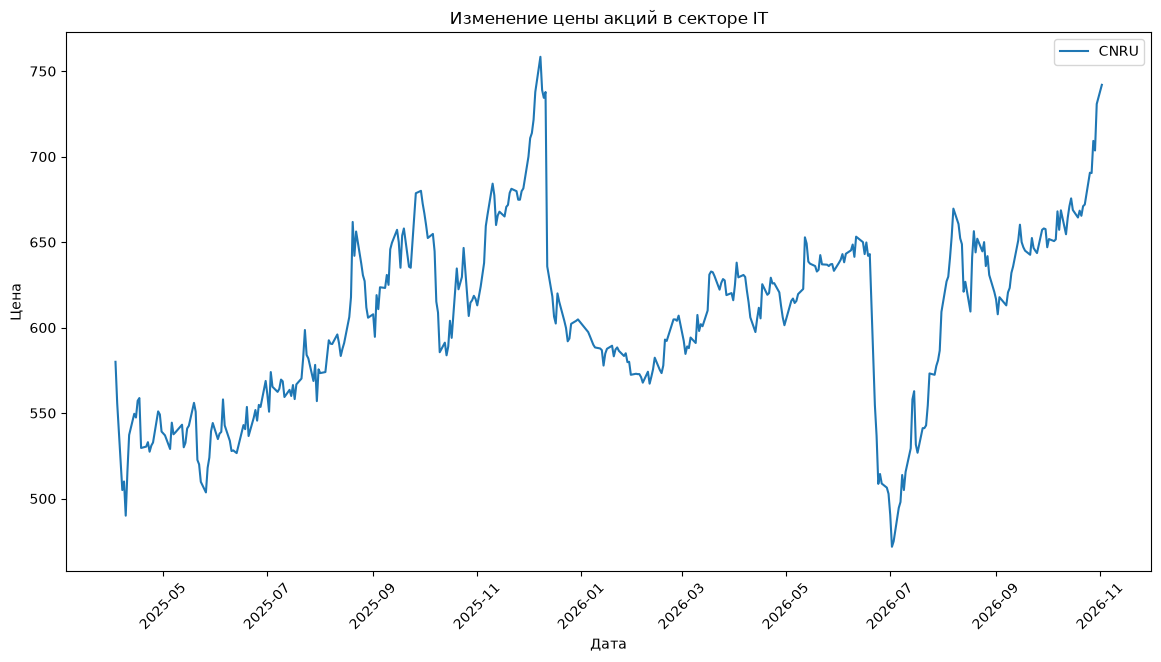

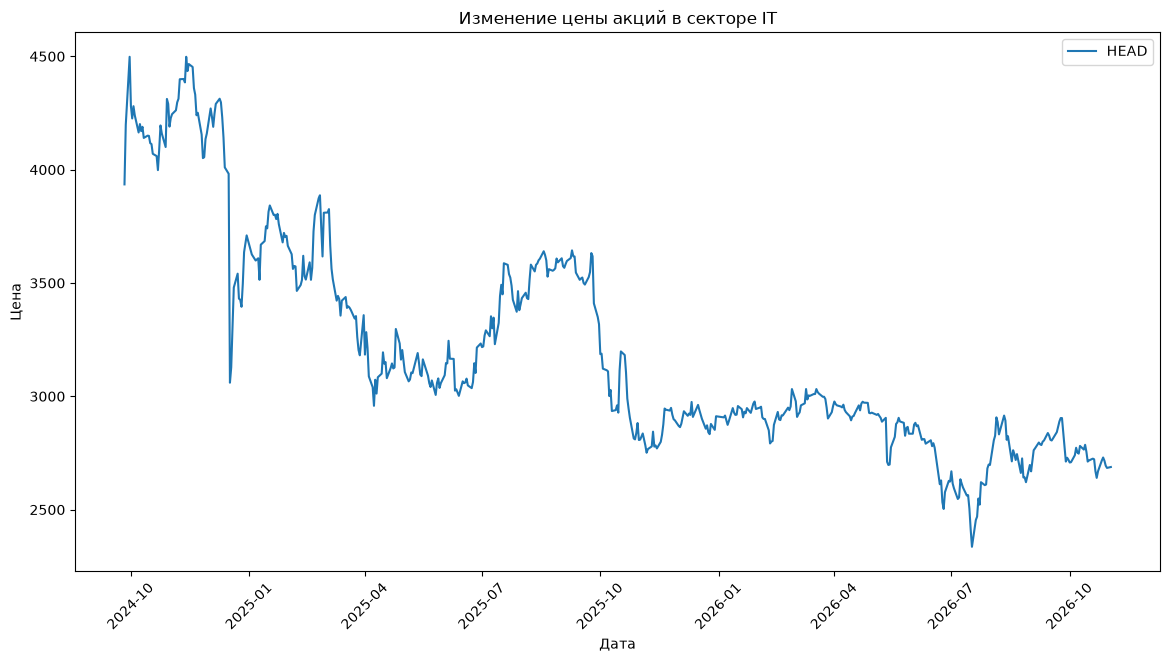

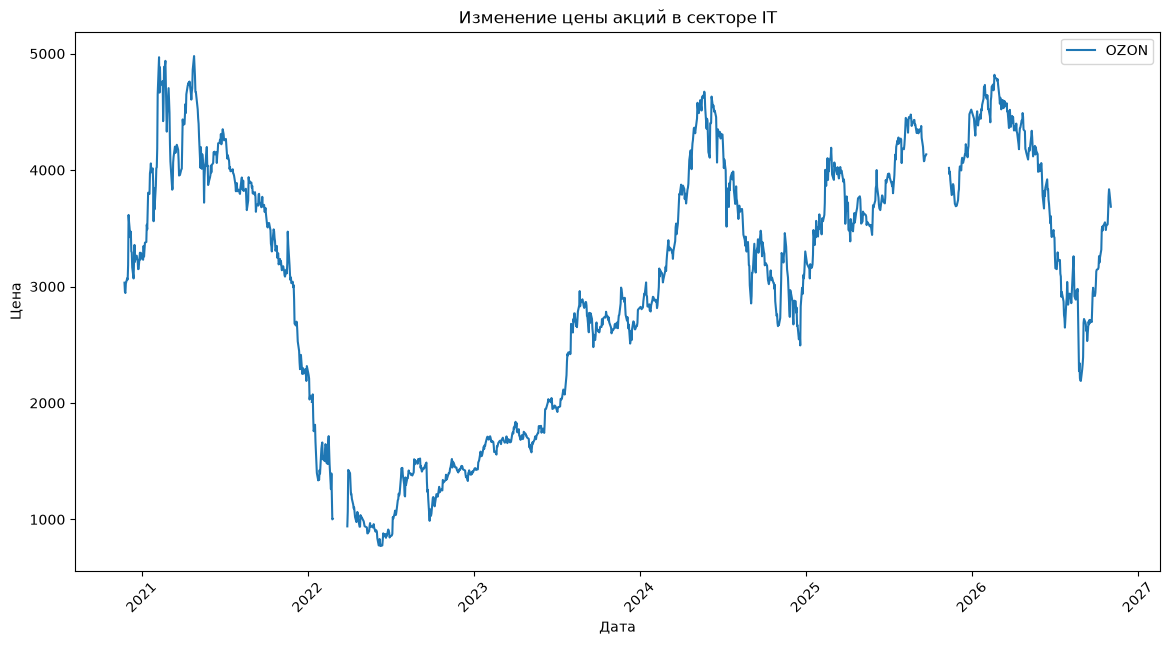

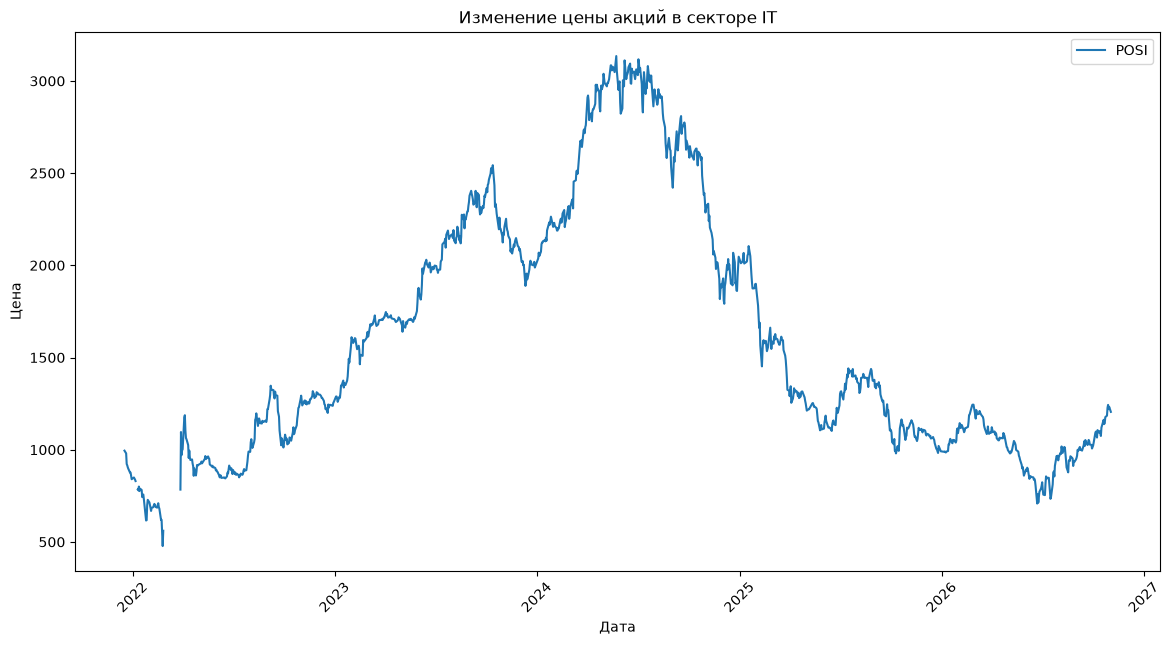

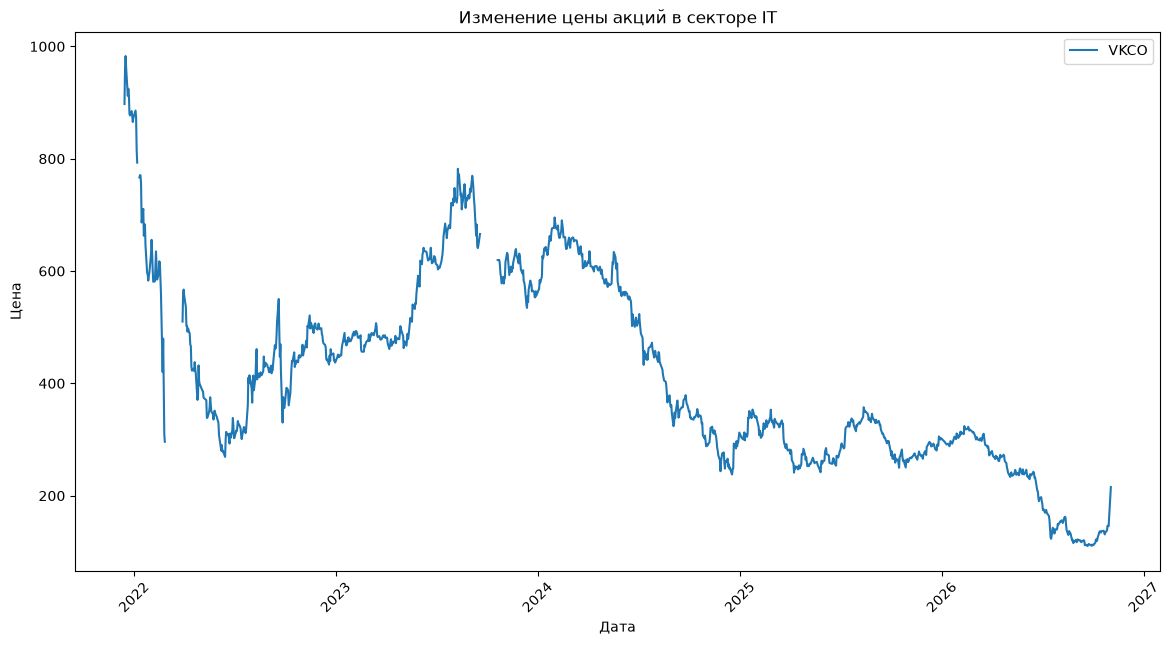

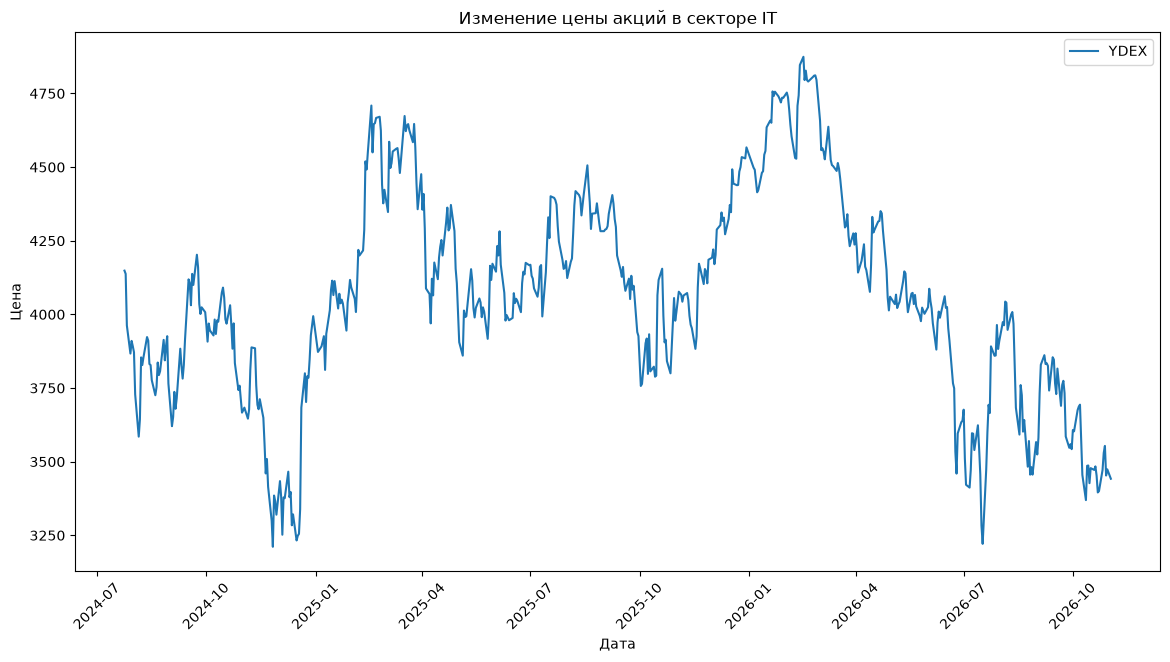

In [44]:

for ticker in IT:
	plt.figure(figsize=(14, 7))
	plt.xticks(rotation=45)
	ticker_data = data_it_analysis_df[data_it_analysis_df['ticker'] == ticker]
	plt.plot(ticker_data.index, ticker_data['close'], label=ticker)
	plt.xlabel('Дата')
	plt.ylabel('Цена')
	plt.title('Изменение цены акций в секторе IT')
	plt.legend()
	plt.show()

Акции в разных масштабах, для оценки нормализуем к одному масштабу и сравним с индексом:

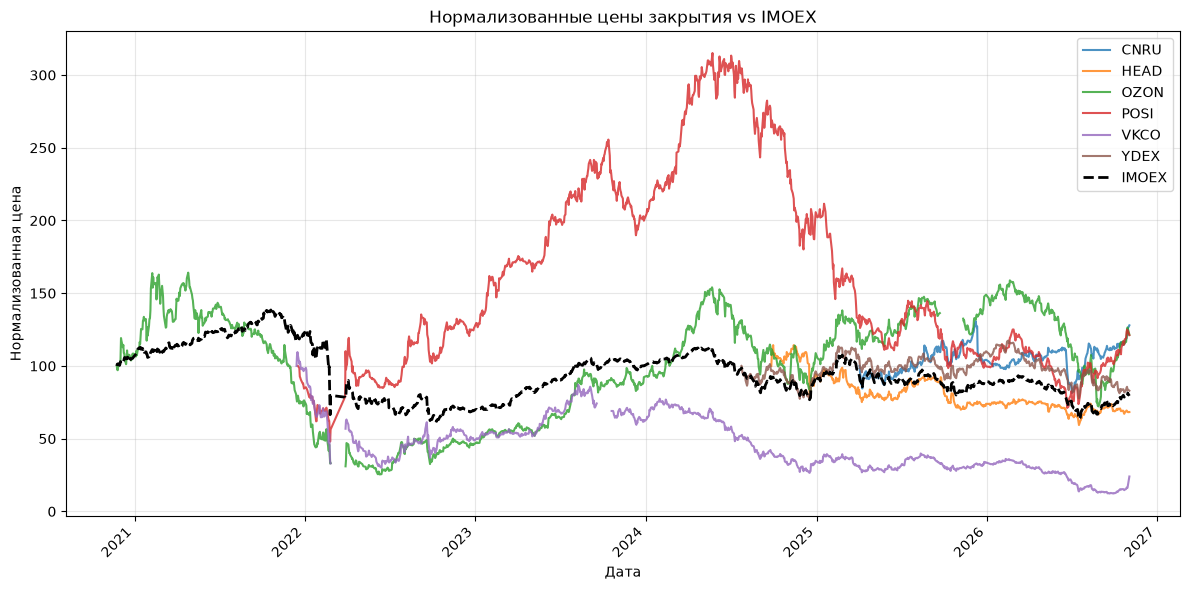

In [17]:
prices_pivot =  data_it_analysis_clean_df.pivot(columns='ticker', values='close')
prices_pivot.index=pd.to_datetime((prices_pivot.index))
imoex = data_it_analysis_clean_df.groupby('trade_date')['close_ix'].first()
imoex.index=pd.to_datetime((imoex.index))

# Нормализуем все акции сектора к 100.
norm_prices = prices_pivot.apply(lambda col:(col.dropna() / col.dropna().iloc[0]) * 100)
norm_imoex = (imoex / imoex.iloc[0]) * 100



plt.figure(figsize=(12, 6))
for col in norm_prices.columns:
    plt.plot(norm_prices.index, norm_prices[col],label=col, alpha=0.8)
plt.plot(norm_imoex.index, norm_imoex, label='IMOEX', color='black', linewidth=2,linestyle='--')
plt.title('Нормализованные цены закрытия vs IMOEX')
plt.xlabel('Дата')
plt.xticks(rotation=45,ha='right')
plt.ylabel('Нормализованная цена')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Любопытно, что акции Озона и ВК сильно коррелируют до конца 2024 года, после чего акции ВК значительно теряют в цене. Также есть динамика POSI, в сравнении с MOEX и другими компаниями сектора - после 2022 акции значительно выше индекса. Думаю связано с импортозамещением и потребностью в информационной безопасности.

---
*Видно также, что акции YDEX отсутствуют ранее 2024 года, что связано со сменой юрлица.*



### Дневное распределение доходности
---
- Посчитаем логарифм дневного распределения доходности.
- Среднее, стандартное отклонение (волатильность), скос и куртозис/эксцесс.
- Покажем отклонение от нормального распределения.

In [18]:
data_it = data_it_analysis_clean_df.sort_values(['ticker',
'trade_date']).copy()
data_it['return'] = data_it.groupby('ticker')['close'].pct_change()
data_it['log_ret'] = np.log(data_it['close'] /
data_it.groupby('ticker')['close'].shift(1))

# Summary statistics table
stats = data_it.groupby('ticker')['return'].agg(
    Mean='mean',
    Daily_Vol='std',
    Annual_Vol=lambda x: x.std() * np.sqrt(252), # 252 среднее число торговых дней на бирже
    Skew=lambda x: x.skew(),
    Kurtosis=lambda x: x.kurtosis()).round(4)

print("Return Risk Profiles:")
display(stats)

Return Risk Profiles:


,Mean,Daily_Vol,Annual_Vol,Skew,Kurtosis
ticker,,,,,
CNRU,0.0008,0.0213,0.3378,-1.4293,9.4853
HEAD,-0.0005,0.0207,0.3279,-2.4079,29.6412
OZON,0.0007,0.0323,0.5125,0.4435,15.9951
POSI,0.0006,0.0300,0.4765,3.7094,55.0796
VKCO,-0.0004,0.0406,0.6443,4.5256,93.9818
YDEX,-0.0001,0.0197,0.3132,0.5497,1.8383


Наличие высоких значений куртозиса говорит о сильном отклонении от нормального распределения и высоком риске инвестиций в такие акции. Куртозис около 0 означал бы низкий риск аномальных отклонений.

---

Учет куртозиса критически важен в оценке риска инвестиций.

Посчитаем волатильность за 20 торговых дней.

---

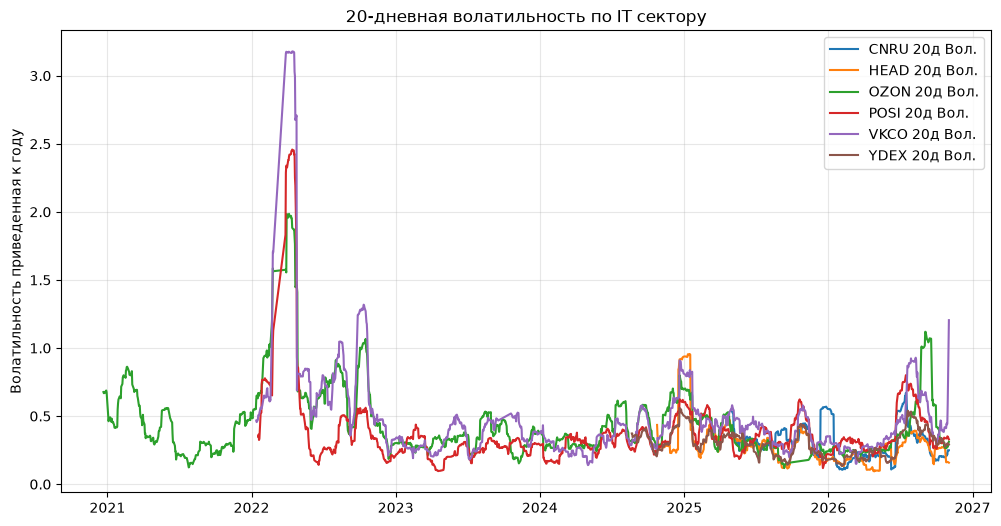

In [20]:
data_it['vol_20d'] = (
        data_it.groupby('ticker')['return']
        .rolling(window=20)
        .std()
        .reset_index(level=0, drop=True) * np.sqrt(252)
    )

plt.figure(figsize=(12, 6))
for ticker in IT:
    subset = data_it[data_it['ticker'] == ticker]
    plt.plot(subset.index, subset['vol_20d'], label=f'{ticker} 20д Вол.')
plt.title('20-дневная волатильность по IT сектору')
plt.ylabel('Волатильность приведенная к году')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Видно, что акции сектора в основном коррелируют между собой, скачки волатильности повторяются.

Построим матрицу корреляций.

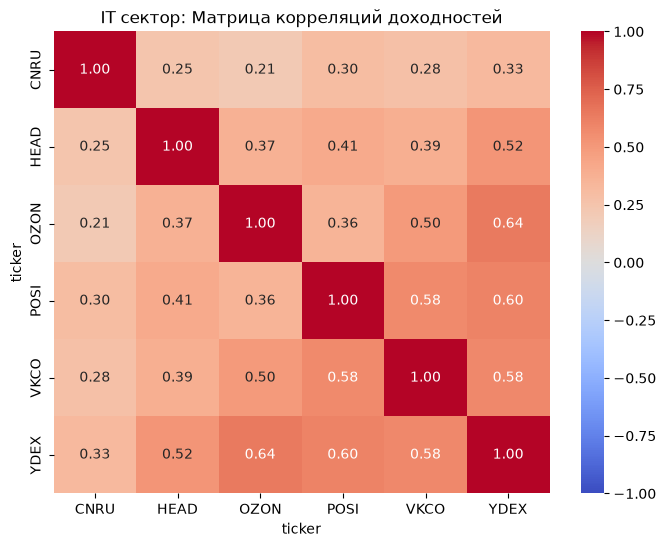

In [46]:
returns_pivot = data_it.pivot_table(
    index=data_it.index,
    columns='ticker',
    values='return'
)

corr_matrix = returns_pivot.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(returns_pivot.corr(), annot=True, cmap='coolwarm',
fmt=".2f", vmin=-1, vmax=1)
plt.title('IT сектор: Матрица корреляций доходностей')
plt.show()

в рамках анализа можно сделать вывод, что держать в портфеле акции одного сектора рискованно.

Построим матрицу корреляций для всего рынка

---

In [92]:
full_data=data.dropna(subset=['close']).sort_values(['ticker','trade_date'])
full_data['return']=full_data.groupby('ticker')['close'].pct_change()

In [74]:
ticker_sector_map=(full_data[['ticker','sector']].drop_duplicates().sort_values(['sector','ticker']))
tickers=ticker_sector_map['ticker'].to_list()

In [78]:
sector_size=ticker_sector_map.groupby('sector').size()
bounds=np.cumsum(sector_size)[:-1]

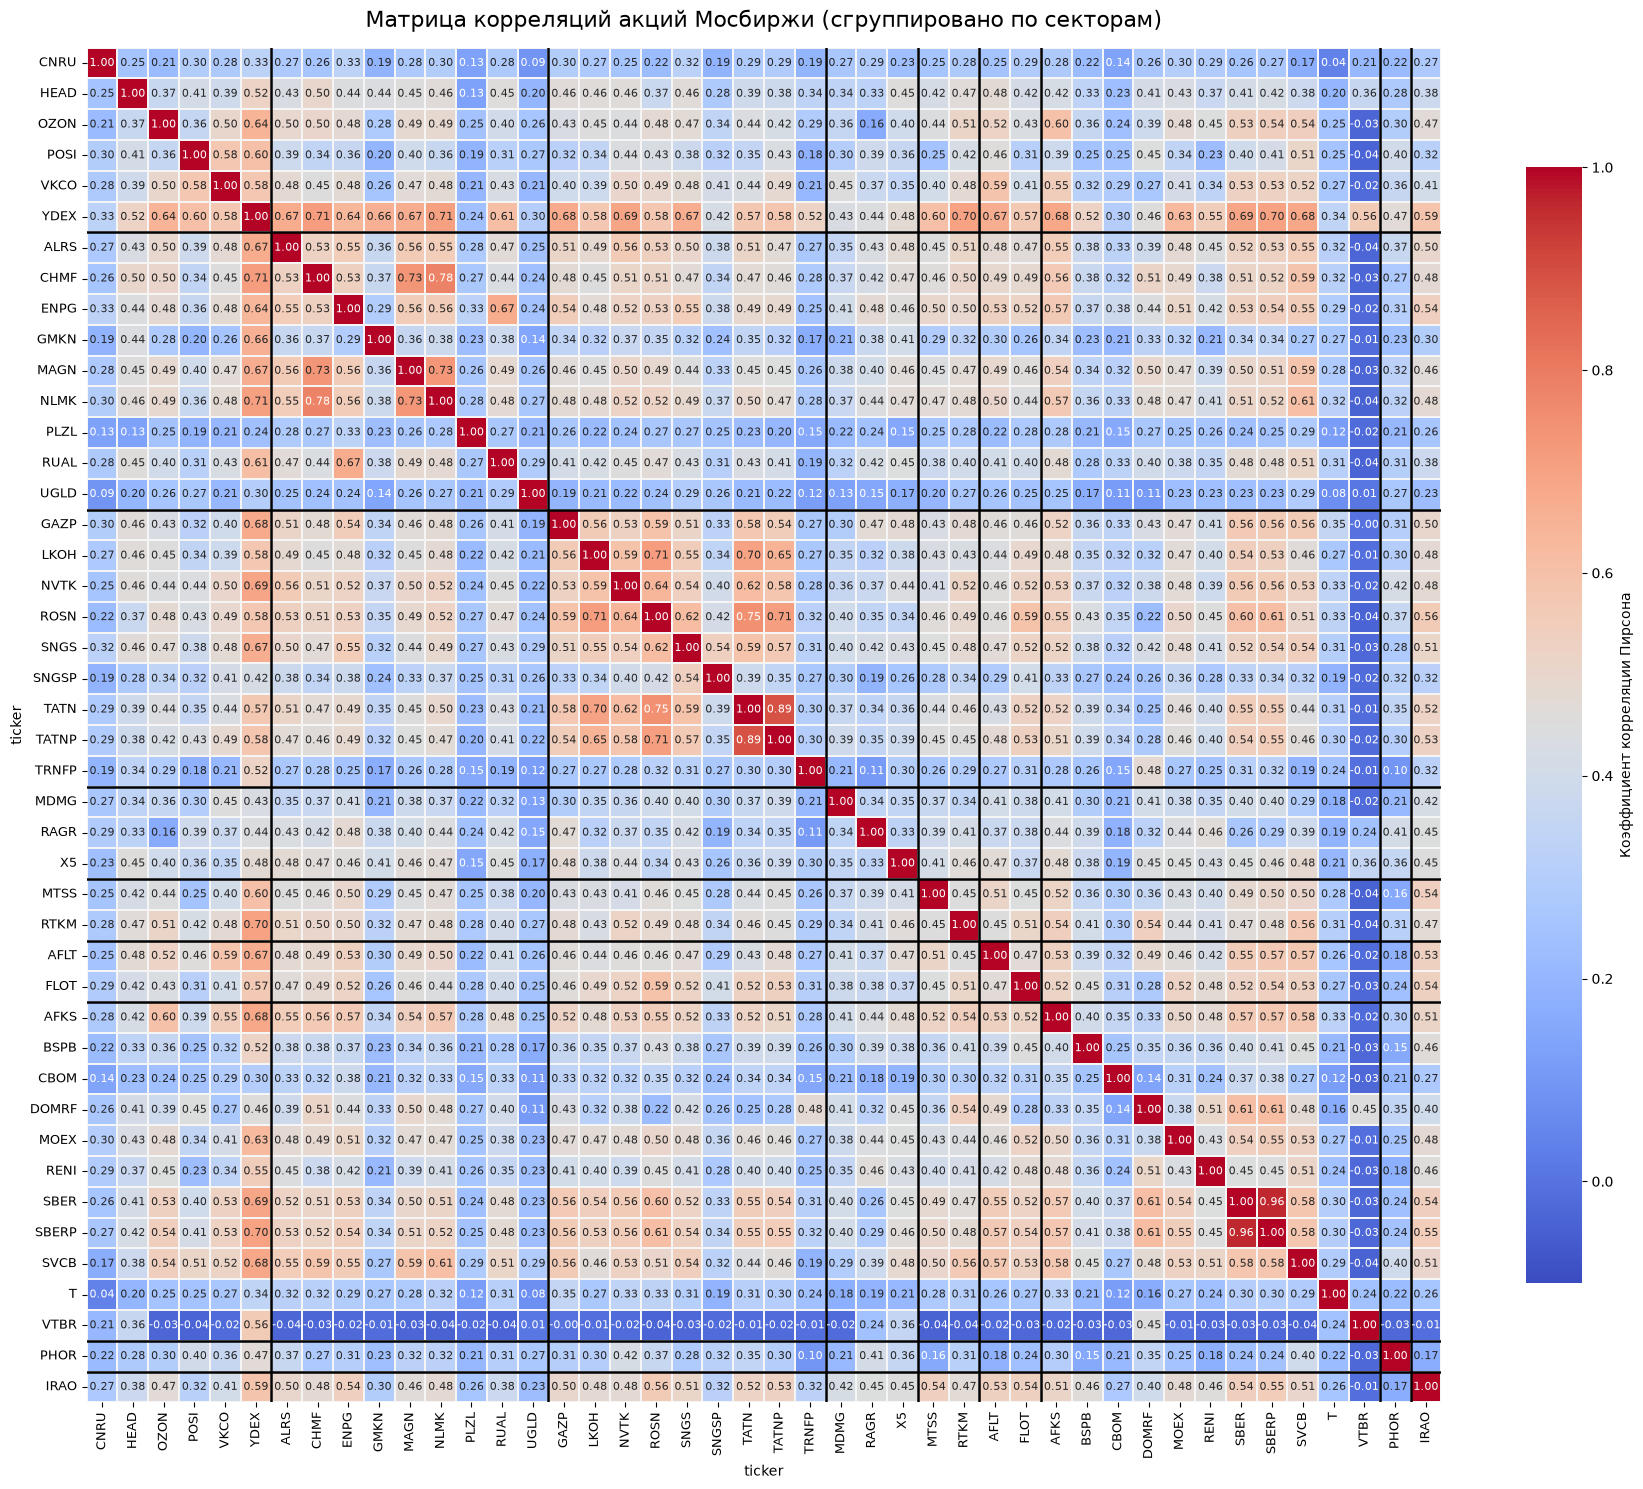

In [85]:
plt.figure(figsize=(18, 15))

pivot_returns = full_data.pivot(index='trade_date', columns='ticker', values='return')
full_corr_matrix = pivot_returns.corr().loc[tickers, tickers]

ax = sns.heatmap(full_corr_matrix,cmap='coolwarm',vmin=-0.1,vmax=1.0,square=True,linewidths=0.2,linecolor='whitesmoke',annot=True,annot_kws={'size': 8},fmt='.2f',cbar_kws={'shrink': 0.8, 'label': 'Коэффициент корреляции Пирсона'})


for b in bounds:
    ax.axhline(b, color='black', linewidth=1.8, linestyle='-')
    ax.axvline(b, color='black', linewidth=1.8, linestyle='-')

plt.title('Матрица корреляций акций Мосбиржи (сгруппировано по секторам)', fontsize=16, pad=15)
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

Значительная корреляция внутри секторов (разделены линиями), также заметна корреляция между нефтяными и металлообразующими компаниями (связь с экспортом и курсом валюты) и низкая между ними, говорит о том, что имеет смысл диверсификация портфеля.


## Cезонность, стационарность, тренд.

---

1. Проверим на стационарность на примере графика OZON.

In [48]:
from statsmodels.tsa.stattools import adfuller

def test_stationarity(series, name="Series"):
    clean_series = series.dropna()
    result = adfuller(clean_series, autolag='AIC',result_object=False)

    adf_stat = result[0]
    p_value = result[1]
    crit_values = result[4]

    is_stationary = p_value < 0.05
    status = "СТАЦИОНАРЕН " if is_stationary else "НЕСТАЦИОНАРЕН ❌"

    print(f"[{name}] ADF Statistic: {adf_stat:.4f}, p-value:{p_value:.4e} -> {status}")

# Проверяем для одного из тикеров (например, OZON):
ozon_data = data_it[data_it['ticker'] == 'OZON']

print("--- 1. Проверка ЦЕНЫ закрытия ---")
test_stationarity(ozon_data['close'], name="OZON Close Price")

print("\n--- 2. Проверка ДОХОДНОСТЕЙ (returns) ---")
test_stationarity(ozon_data['return'], name="OZON Daily Return")

--- 1. Проверка ЦЕНЫ закрытия ---
[OZON Close Price] ADF Statistic: -1.3113, p-value:6.2401e-01 -> НЕСТАЦИОНАРЕН ❌

--- 2. Проверка ДОХОДНОСТЕЙ (returns) ---
[OZON Daily Return] ADF Statistic: -7.3860, p-value:8.2348e-11 -> СТАЦИОНАРЕН 


Видим, что график доходностей стационарен, в отличии от графика цены.

2. Проверим на тренд. Используем скользящие средние SMA 50 и SMA 200

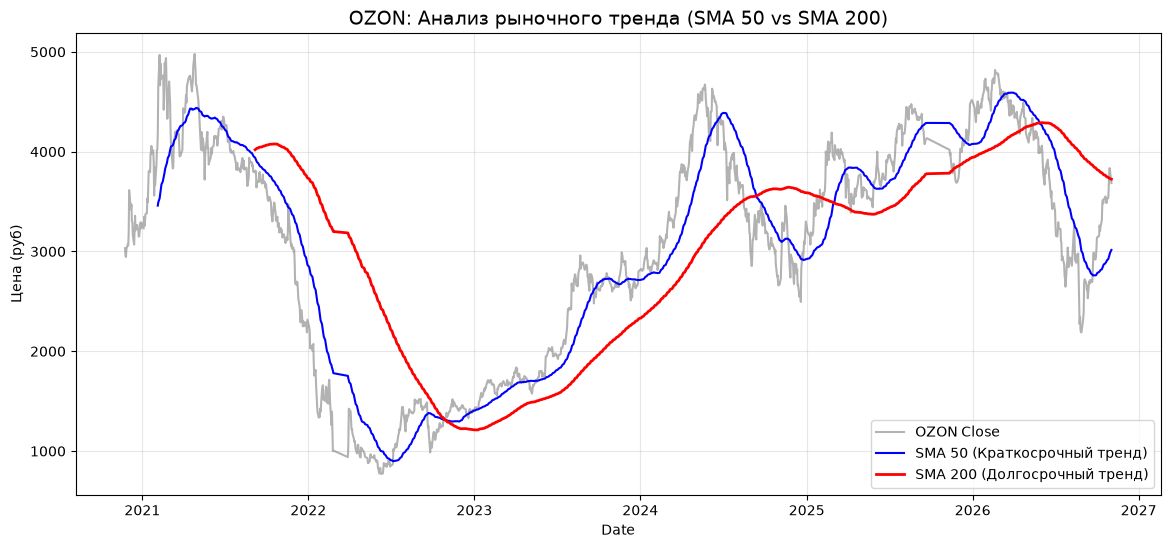

In [49]:
ozon_close = ozon_data['close'].copy()

sma_50 = ozon_close.rolling(window=50).mean()
sma_200 = ozon_close.rolling(window=200).mean()

plt.figure(figsize=(14, 6))
plt.plot(ozon_close.index, ozon_close, label='OZON Close',
color='gray', alpha=0.6)
plt.plot(sma_50.index, sma_50, label='SMA 50 (Краткосрочный тренд)',
color='blue', linewidth=1.5)
plt.plot(sma_200.index, sma_200, label='SMA 200 (Долгосрочный тренд)',
color='red', linewidth=2)

plt.title('OZON: Анализ рыночного тренда (SMA 50 vs SMA 200)',
fontsize=14)
plt.xlabel('Date')
plt.ylabel('Цена (руб)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Тренд цены стохастический. Обычная линейная регрессия не эффективна.

3. Проверим на сезонность.

---

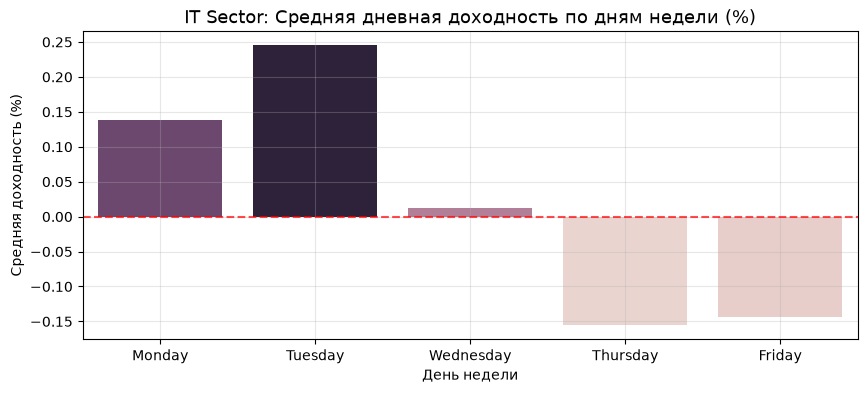

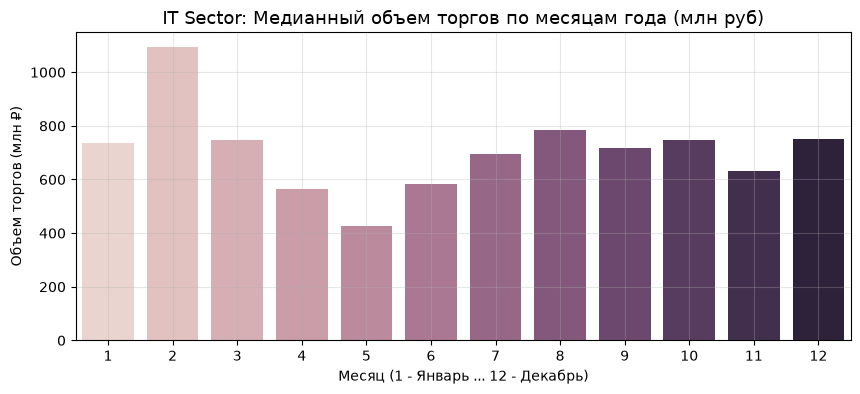

In [54]:
data_it['day_name'] = data_it.index.day_name()
data_it['month'] = data_it.index.month

# 2. График средней доходности по дням недели
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
avg_by_day = data_it.groupby('day_name')['return'].mean().reindex(day_order) * 100

plt.figure(figsize=(10, 4))
sns.barplot(x=avg_by_day.index, y=avg_by_day.values, hue=avg_by_day,legend=False)
plt.axhline(0, color='red', linestyle='--', alpha=0.7)
plt.title('IT Sector: Средняя дневная доходность по дням недели (%)',fontsize=13)
plt.ylabel('Средняя доходность (%)')
plt.xlabel('День недели')
plt.grid(True, alpha=0.3)
plt.show()

# 3. График объемов торгов по месяцам (сезонность активности)
monthly_volume = data_it.groupby('month')['value'].median() / 1e6

plt.figure(figsize=(10, 4))
sns.barplot(x=monthly_volume.index, y=monthly_volume.values,hue=monthly_volume.index,legend=False)
plt.title('IT Sector: Медианный объем торгов по месяцам года (млн руб)', fontsize=13)
plt.xlabel('Месяц (1 - Январь ... 12 - Декабрь)')
plt.ylabel('Объем торгов (млн ₽)')
plt.grid(True, alpha=0.3)
plt.show()

---

Видно, что к концу недели многие консолидируют прибыль. По месяцам тоже можно заметить некоторую закономерность, затишье в летний период, дивидендный сезон.

4. Автокорреляция.

---

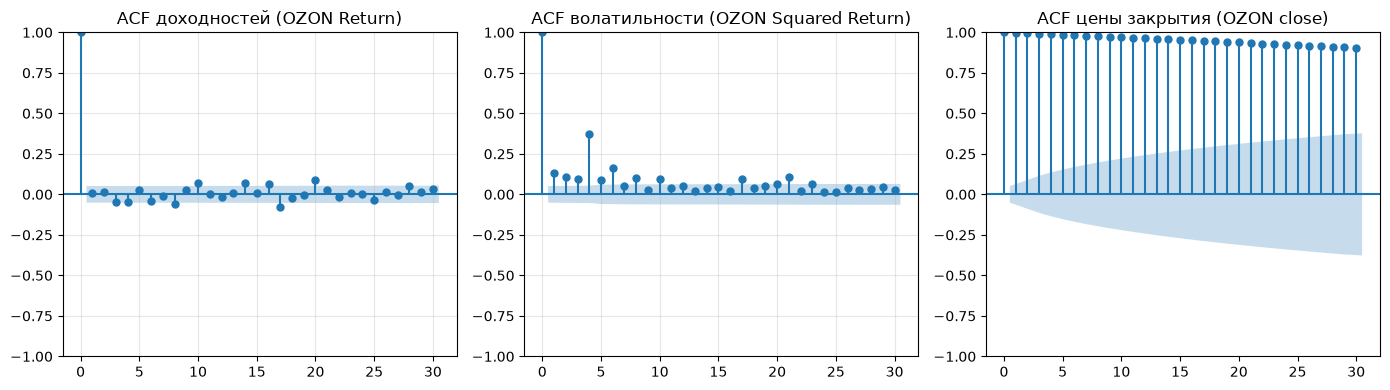

In [56]:
from statsmodels.graphics.tsaplots import plot_acf

ozon_ret = ozon_data['return'].dropna()
ozon_close=ozon_data['close'].dropna()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

plot_acf(ozon_ret, lags=30, ax=axes[0], title='ACF доходностей (OZON Return)')
axes[0].grid(True, alpha=0.3)

plot_acf(ozon_ret**2, lags=30, ax=axes[1], title='ACF волатильности (OZON Squared Return)')
axes[1].grid(True, alpha=0.3)

plot_acf(ozon_close,lags=30, ax=axes[2], title='ACF цены закрытия (OZON close)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Высокая автокорреляция цены - зависимость от предыдущего значения - нельзя использовать в в линейной регрессии - цена просто естественно похожа на предыдущие значения, это даст ложную корреляцию. И низкая автокорреляция для значений доходностей - нельзя предсказать поведение исходя из предыдущих значений. При этом квадраты доходностей выходят за голубые границы - есть кластеризация волатильности на лагах до 1-6,8,10,17,21 - если вчера был всплеск волатильности, то с высокой вероятностью сохранится и через неделю. Такое поведение можно использовать в прогнозе модели.